# 08 — 라벨 노이즈: 반복 실험 재현성과 `|comb_t| ≥ 2` 기준 (`results/label_noise`)

Fitness Browser 의 무자극 적합도는 대부분의 유전자에서 0 근처의 작은 값이고, 반복 실험 사이에 부호조차 자주 바뀐다.
이 노트북은 (1) 라벨이 얼마나 흔들리는지, (2) 적합도 모델의 조기 종료 · 평가에 쓰는 `|comb_t| ≥ 2` 기준이
**라벨 일관성**과 **샘플 규모** 사이에서 왜 적절한지를 반복 실험만으로 보인다.

**설계 — 한쪽 반복으로 고르고, 다른 쪽 반복으로 확인**
- Time0 집합(시작 시료)이 2개 이상인 24균주는 무자극 실험을 집합 단위로 A · B 두 반쪽으로 나눌 수 있다. 시작 시료가 달라 두 반쪽은 서로 독립인 반복 측정이다
- 반쪽마다 01 노트북 3.2 · 3.3절과 같은 공식으로 $fit_A$ · $t_A$ ($fit_B$ · $t_B$ 도 같음)를 구한다
- 기준 $\tau$ 로 **A 에서** 유전자를 고르고, 고른 유전자가 **B 에서** 재현되는지 본다 (B 로 고르고 A 로 확인한 결과도 합친다)
- 전체 자료의 `comb_t` 로 고르고 같은 자료로 일치도를 재면 안 된다. 우연히 큰 값이 나온 유전자가 뽑혀 재현성이 부풀려진다

| 절 | 내용 | 그림 (`results/label_noise/`) |
|---|---|---|
| 1 | 반쪽 분할 | — |
| 2 | 기준값별 재현성 · 남는 유전자 수 (주 그림) | `fig1_tau_curve.png` |
| 3 | 적합도 모델 교차검증 예측 읽기 | — |
| 4 | 노이즈 천장 대비 모델 성능 | `fig2_noise_ceiling.png` |
| 5 | 반쪽 산점도 (보조) | `fig3_halves_hexbin.png` |
| 6 | 평가 기준값에 따른 모델 성능 (보조) | `fig4_threshold_sensitivity.png` |
| 7 | 정리 — `|comb_t| ≥ 2` 의 근거 | — |

> **입력** — 01 노트북의 `data/basedata/*.tsv` 와 `data/fitness_browser/feba.db` (실험별 fit · t), 04 노트북의 적합도 모델 교차검증 결과 `results/fitpred_ablation/noseq` (서비스 모델, 3 · 4 · 6절). GPU 없이 수 분이면 끝난다.

**산출물** (`results/label_noise/`) — `halves.tsv.gz` (유전자별 반쪽 값), `tau_curve.csv`, `ceiling.csv`, `sensitivity.csv`, 그림 4개


In [1]:
# !pip install pandas scipy matplotlib
import os, glob, sqlite3, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from proteomefit import data

warnings.filterwarnings('ignore')
DB        = '../data/fitness_browser/feba.db'        # Fitness Browser 실험별 fit · t (01 노트북 입력)
BASE_DIR  = '../data/basedata'                       # 균주별 base data TSV (01 노트북)
FIT_SRC   = '../results/fitpred_ablation/noseq'      # 서비스 적합도 모델의 교차검증 예측 (04 노트북)
NOISE_DIR = '../results/label_noise'                 # 산출물 (그림 · 표)
T_SEL     = 2.0                                      # 학습 · 평가에 쓰는 |comb_t| 기준
TAUS      = np.round(np.arange(0, 6.01, 0.25), 2)    # 살펴볼 기준값 [25]
os.makedirs(NOISE_DIR, exist_ok=True)
con = sqlite3.connect(DB)

# 균주별 무자극 실험 목록 - 01 노트북 1절과 같다 (base data TSV 순번 = 이 순서)
NOSTRESS = {
    'acidovorax_3H11'           : ['set3IT059', 'set3IT060'],
    'ANA3'                      : ['set4IT075'],  # ★다른 배양온도
    'azobra'                    : ['set1IT052', 'set1IT060'],  # ★다른 배양온도
    'BFirm'                     : ['set2IT067'],
    'Btheta'                    : ['set1IT071', 'set1IT072', 'set4IT047', 'set4IT050'],  # ‡다른 배지 §정의배지
    'Burk376'                   : ['set1IT043', 'set1IT044', 'set4IT079', 'set4IT088'],  # ‡다른 배지 §정의배지
    'Caulo'                     : ['set8IT011', 'set8IT023', 'set8IT035'],
    'Cola'                      : ['set1IT035', 'set1IT048', 'set1IT079', 'set2IT011', 'set2IT024', 'set2IT034', 'set2IT045', 'set2IT058', 'set2IT068'],
    'Cup4G11'                   : ['set4IT069', 'set5IT004', 'set5IT012'],
    'Dda3937'                   : ['set9TCH417', 'set9TCH418', 'set9TCH419', 'set9TCH420', 'setATCH110', 'setATCH111', 'setATCH112', 'setATCH191', 'setATCH192'],  # ★다른 배양온도
    'Ddia6719'                  : ['setATCH203', 'setATCH204', 'setATCH206', 'setATCH207'],  # ★다른 배양온도
    'DdiaME23'                  : ['set10TCH436', 'set10TCH438', 'setATCH113', 'setATCH114', 'setATCH115', 'setATCH240', 'setATCH241', 'setATCH242'],  # ★다른 배양온도
    'Dino'                      : ['set7IT086', 'set7IT087'],  # †품질 이탈 제외
    'DvH'                       : ['set1S209', 'set1S210', 'set1S211', 'set2S268', 'set2S269', 'set2S270', 'set3S344', 'set3S345', 'set3S346', 'set4IT040', 'set4IT041', 'set4IT042'],
    'Dyella79'                  : ['set3IT040', 'set3IT051', 'set3IT060', 'set3IT067'],
    'HerbieS'                   : ['set12IT038', 'set12IT039', 'set12IT040', 'set13IT052', 'set13IT053', 'set13IT054'],  # ‡다른 배지 ‖다른 라이브러리
    'Kang'                      : ['set2H11', 'set2H20', 'set2H43', 'set2H48'],  # †품질 이탈 제외
    'Keio'                      : ['set2IT045', 'set2IT069'],  # ★다른 배양온도
    'Korea'                     : ['set5IT075', 'set5IT076'],
    'Koxy'                      : ['set6IT088', 'set7IT016', 'set7IT054', 'set7IT071', 'set7IT078'],
    'Magneto'                   : ['set1IT053'],
    'Marino'                    : ['set2H22', 'set2H31', 'set2H41', 'set3H25', 'set3H30', 'set3H31', 'set3H39', 'set3H7', 'set4H10', 'set4H18', 'set4H30'],
    'Miya'                      : ['set2IT012', 'set2IT016', 'set2IT025'],
    'MR1'                       : ['set1H15', 'set2H29', 'set2H44', 'set4H43', 'set4H48', 'set5H12', 'set5H44', 'set5H47', 'set6H11', 'set6H18', 'set6H25', 'set6H7'],
    'Pedo557'                   : ['set1IT019', 'set1IT034', 'set1IT053', 'set1IT068', 'set1IT095', 'set2IT008', 'set2IT022', 'set2IT032', 'set2IT041'],
    'Phaeo'                     : ['set2H31', 'set2H43', 'set2H5', 'set3H7', 'set4H18', 'set6IT009', 'set6IT016', 'set6IT030', 'set6IT041', 'set7IT053', 'set7IT062', 'set7IT073', 'set7IT085', 'set8IT088', 'set8IT096'],
    'Ponti'                     : ['set1IT035', 'set1IT045', 'set1IT063', 'set1IT073', 'set2IT084', 'set2IT096', 'set3IT015', 'set3IT028', 'set3IT040', 'set3IT055'],
    'PS'                        : ['set1H13', 'set1H15', 'set1H16'],
    'pseudo1_N1B4'              : ['set5IT018'],
    'pseudo3_N2E3'              : ['set6IT053', 'set6IT054'],
    'pseudo5_N2C3_1'            : ['set6IT074', 'set6IT075'],
    'pseudo6_N2E2'              : ['set3IT072', 'set3IT076', 'set3IT082', 'set3IT085'],
    'pseudo13_GW456_L13'        : ['set2IT087'],  # ★다른 배양온도
    'psRCH2'                    : ['set3H43', 'set4H19', 'set4H37', 'set4H6', 'set5H14', 'set5H5'],
    'Putida'                    : ['set36IT074', 'set36IT075', 'set36IT076', 'set38IT007', 'set38IT010', 'set38IT011'],  # ‡다른 배지 ‖다른 라이브러리
    'PV4'                       : ['set1H1', 'set1H25', 'set1H6', 'set3IT055'],
    'RalstoniaBSBF1503'         : ['set1IT076', 'set1IT080', 'set3IT039'],
    'RalstoniaGMI1000'          : ['set2IT062', 'set4IT033'],
    'RalstoniaPSI07'            : ['set1IT085', 'set1IT089'],
    'RalstoniaUW163'            : ['set1IT067', 'set1IT071', 'set2IT036'],
    'SB2B'                      : ['set1H42', 'set1H43', 'set1H44', 'set2H12', 'set2H6', 'set2H7', 'set4H10', 'set4H20', 'set4H34', 'set4H42', 'set5H11', 'set5H23', 'set5H7', 'setAH41'],
    'Smeli'                     : ['set2IT069', 'set2IT070'],
    'SynE'                      : ['set3IT004', 'set3IT016', 'set3IT031', 'set4IT050', 'set4IT062', 'set4IT077', 'set4IT089', 'set7IT032', 'set7IT042', 'set7IT047', 'set8IT052', 'set8IT057', 'set8IT062', 'set8IT066', 'set8IT069', 'set8IT080', 'set8IT085', 'set8IT090'],
    'SyringaeB728a'             : ['set1IT005', 'set4IT013'],
    'SyringaeB728a_mexBdelta'   : ['set1IT006', 'set4IT014'],
    'WCS417'                    : ['set18IT044'],  # ‡다른 배지
}
print(f'organisms {len(NOSTRESS)} | no-stress experiments {sum(map(len, NOSTRESS.values()))}')


# 결합 통계량 - 01 노트북 3.3절과 같은 함수
def combine_reps(SE, T, ok, gid, n_group):
    """
    SE, T   : [n_gene, n_exp] 표준오차·유사 t (무효 칸은 NaN)
    ok      : [n_gene, n_exp] 유효 마스크
    gid     : [n_exp] 실험별 Time0 집합 번호 (같은 번호 = 같은 시작 시료 공유)
    n_group : Time0 집합 개수
    반환    : (comb_se [n_gene], comb_t [n_gene]) - 유효 실험 0개인 유전자는 NaN
    """
    okf = ok.astype(float)
    n   = ok.sum(1)
    M   = np.zeros((len(gid), n_group))                    # one-hot [n_exp, n_group]
    M[np.arange(len(gid)), gid] = 1.0

    ng = okf @ M                                           # [n_gene, n_group] 그룹별 유효 실험 수
    Sg = np.where(ok, SE, 0.0) ** 2 @ M                    # [n_gene, n_group] 그룹별 se^2 합
    Tg = np.where(ok, T, 0.0) @ M                          # [n_gene, n_group] 그룹별 t 합

    with np.errstate(invalid='ignore', divide='ignore'):
        comb_se = np.sqrt(((ng + 1) * Sg).sum(1) / (2 * n ** 2))          # fit_mean의 표준오차
        tg      = np.where(ng > 0, Tg / np.sqrt(ng * (ng + 1) / 2), 0.0)  # 그룹 안 - 공유 보정
        comb_t  = tg.sum(1) / np.sqrt((ng > 0).sum(1))                    # 그룹 사이 - Stouffer
    comb_se[n == 0] = comb_t[n == 0] = np.nan
    return comb_se, comb_t


organisms 46 | no-stress experiments 226


## 1. 반쪽 분할

- Time0 집합은 통째로 한쪽에 넣는다. 같은 시작 시료를 쓴 실험이 양쪽에 갈라지면 두 반쪽이 독립이 아니게 된다
- 실험 수가 많은 집합부터 실험이 적은 반쪽에 배정해 두 반쪽의 실험 수를 맞춘다
  - 예: 집합 크기가 [4, 3, 2] 이면 4 → A, 3 → B, 2 → B (A 4개 · B 5개)
- 비필수(measured) 유전자 중 두 반쪽 모두 값이 있는 유전자만 쓴다
- Time0 집합이 1개뿐인 22균주는 나눌 수 없어 1 · 2 · 4 · 5절에서 빠진다 (6절은 46균주 전체)


In [2]:
def split_halves(gid):
    """
    gid  : [n_exp] 실험별 Time0 집합 번호
    반환 : [n_exp] 반쪽 번호 (0 = A, 1 = B). 집합은 통째로 한쪽에 넣고, 실험이 많은 집합부터 실험이 적은 반쪽에 배정
    예   : gid [0, 0, 1, 2] -> [0, 0, 1, 1]
    """
    size = np.bincount(gid)
    half, load = np.zeros(len(size), int), [0, 0]
    for g in np.argsort(-size, kind='stable'):
        h = int(load[1] < load[0])
        half[g], load[h] = h, load[h] + size[g]
    return half[gid]


def half_stats(F, SE, T, ok, gid, sel):
    """
    F, SE, T, ok : [n_gene, n_exp] 실험별 fit · 표준오차 · 유사 t · 유효 마스크 (01 노트북 5절과 같은 행렬)
    gid, sel     : [n_exp] Time0 집합 번호 · 이 반쪽에 속한 실험
    반환         : (fit 평균 [n_gene], 결합 t [n_gene]) - 01 노트북 3.3절 공식을 반쪽 실험에만 적용
    """
    g, _ = pd.factorize(gid[sel])
    o = ok[:, sel]
    fit = np.nanmean(np.where(o, F[:, sel], np.nan), 1)
    _, t = combine_reps(SE[:, sel], T[:, sel], o, g, g.max() + 1)
    return fit, t


# Time0 집합 - 실험별 timeZeroSet {org: {expName: tz}}
TZ0 = {}
for o, e, z in con.execute('SELECT orgId,expName,timeZeroSet FROM Experiment'):
    if e in NOSTRESS.get(o, ()):
        TZ0.setdefault(o, {})[e] = z

rows, info = [], []
for i, (org, exps) in enumerate(NOSTRESS.items()):
    gid, _ = pd.factorize(np.asarray([TZ0[org][e] for e in exps], dtype=object))
    if gid.max() < 1:                                                      # Time0 집합 1개 -> 독립 반쪽 불가
        continue
    tsv = pd.read_csv(os.path.join(BASE_DIR, f'{i+1:02d}_{org}.tsv'), sep='\t',
                      usecols=['gene_id', 'fit_mean', 'comb_t'], dtype={'gene_id': str})
    tsv = tsv[np.isfinite(tsv.fit_mean)]                                   # 비필수(measured) 유전자 [m]
    ph  = ','.join('?' * len(exps))
    raw = pd.read_sql(f'SELECT locusId,expName,fit,t FROM FitByExp_{org} WHERE expName IN ({ph})',
                      con, params=exps)
    piv = raw.pivot(index='locusId', columns='expName', values=['fit', 't']).reindex(index=tsv.gene_id)
    F = piv['fit'].reindex(columns=exps).to_numpy(float)                   # [m, n_exp]
    T = piv['t'].reindex(columns=exps).to_numpy(float)
    with np.errstate(invalid='ignore', divide='ignore'):
        SE = np.abs(F) / np.abs(T)
    ok = np.isfinite(F) & np.isfinite(SE)
    F, SE, T = (np.where(ok, M, np.nan) for M in (F, SE, T))
    half = split_halves(gid)
    fa, ta = half_stats(F, SE, T, ok, gid, half == 0)
    fb, tb = half_stats(F, SE, T, ok, gid, half == 1)
    rows.append(pd.DataFrame({'org_id': org, 'gene_id': tsv.gene_id.to_numpy(), 'fit_mean': tsv.fit_mean.to_numpy(),
                              'comb_t': tsv.comb_t.to_numpy(), 'fit_a': fa, 't_a': ta, 'fit_b': fb, 't_b': tb}))
    info.append(dict(org_id=org, n_tz=int(gid.max() + 1), n_exp_a=int((half == 0).sum()),
                     n_exp_b=int((half == 1).sum()), n_gene=len(tsv)))

H    = pd.concat(rows, ignore_index=True).dropna(subset=['fit_a', 'fit_b', 't_a', 't_b'])   # 반쪽 표 [n_h, 8]
INFO = pd.DataFrame(info)
H.to_csv(os.path.join(NOISE_DIR, 'halves.tsv.gz'), sep='\t', index=False, float_format='%.6f')
print(f'split strains {len(INFO)} / {len(NOSTRESS)} | genes with both halves {len(H):,}')
print(INFO.to_string(index=False))


split strains 24 / 46 | genes with both halves 92,013
                 org_id  n_tz  n_exp_a  n_exp_b  n_gene
                 Btheta     2        2        2    4054
                Burk376     2        2        2    5147
                   Cola     2        6        3    3950
                Cup4G11     2        2        1    6373
                Dda3937     3        4        5    3609
               DdiaME23     3        5        3    3606
                    DvH     4        6        6    2725
                HerbieS     2        3        3    3878
                   Koxy     2        4        1    4485
                 Marino     4        6        5    3648
                    MR1     6        6        6    3662
                Pedo557     2        5        4    4359
                  Phaeo     7        8        7    3094
                  Ponti     3        6        4    3643
                 psRCH2     4        3        3    3345
                 Putida     2        3        3   

## 2. 기준값별 재현성과 남는 유전자 수 (주 그림)

기준 $\tau$ 를 0 – 6 으로 바꾸며 $|t_A| \ge \tau$ 로 고른 유전자에 대해 균주별로 아래 값을 구하고, 24균주의 중앙값(선)과 사분위 범위(띠)를 그린다.

| 지표 | 정의 | 읽는 법 |
|---|---|---|
| 부호 일치율 (누적, 파란 선) | $P(\mathrm{sign}\, fit_B = \mathrm{sign}\, fit_A \mid \lvert t_A \rvert \ge \tau)$ | 0.5 = 동전 던지기, 1 = 완벽 재현 |
| 부호 일치율 (구간, 빈 원) | 같은 확률을 $\tau \le \lvert t_A \rvert < \tau + 0.5$ 구간에서 | 기준선 **바로 위**에 걸친 유전자의 신뢰도 |
| 반쪽 간 Spearman $\rho$ (주황 선) | 고른 유전자에서 $\rho(fit_A, fit_B)$ | 순위까지 재현되는 정도 (적합도 모델 평가 지표와 같은 종류) |
| 남는 비율 (아래 칸) | 46균주 비필수 177,317개 중 $\lvert comb\_t \rvert \ge \tau$ 의 비율 | 학습 · 평가에 쓸 수 있는 규모 |

- 예: 유전자 X 가 $fit_A = -1.2$, $t_A = -3.1$ 이면 $\tau = 2$ 에서 선택되고, $fit_B = -0.9$ 이면 부호 일치다.
  유전자 Y 가 $t_A = 1.1$, $fit_B = +0.2$ 이면 $\tau \le 1$ 에서만 선택되고 부호 불일치다
- 반쪽 $t$ 는 실험 수가 절반이라 같은 유전자라도 전체 `comb_t` 보다 절댓값이 작다. 그러나 $t$ 는 "효과 / 표준오차" 라서
  같은 $t$ 값이 뜻하는 신호 대 잡음 비는 실험 수와 무관하다. 그래서 반쪽 $t$ 에서 본 기준값별 재현성을 전체 `comb_t` 기준으로 옮겨 읽는다 (근사)


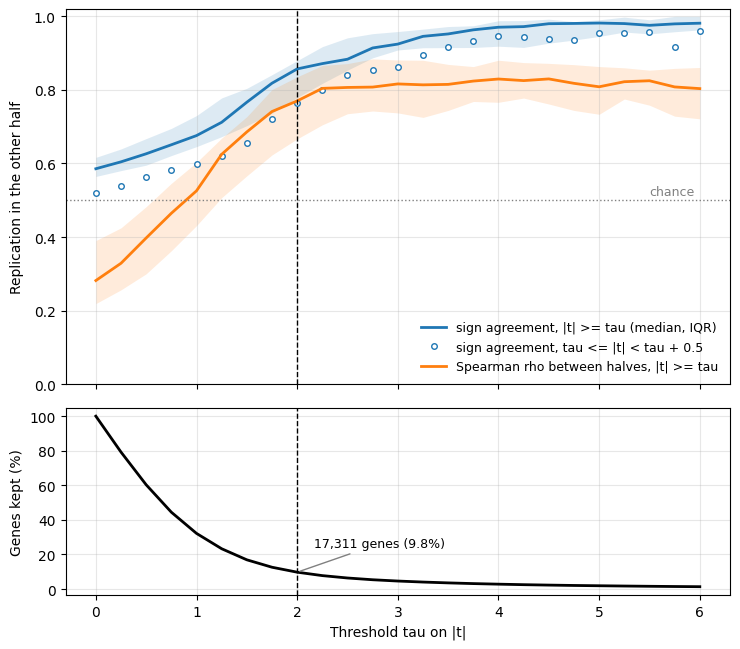

 tau  agree  agree_bin   rho  kept_n  kept_frac
 0.0  0.586      0.521 0.282  177317      1.000
 1.0  0.676      0.598 0.526   57097      0.322
 1.5  0.767      0.655 0.686   30000      0.169
 2.0  0.857      0.763 0.770   17311      0.098
 2.5  0.883      0.841 0.807   11358      0.064
 3.0  0.925      0.862 0.816    8235      0.046
 4.0  0.970      0.946 0.830    5029      0.028
 5.0  0.982      0.955 0.809    3403      0.019


In [3]:
def tau_curve(H, taus, width=0.5, min_n=20):
    """
    H    : 반쪽 표 (fit_a · t_a · fit_b · t_b · org_id)
    taus : 기준값 목록, width : 구간 폭 (구간별 일치율), min_n : 균주별 최소 유전자 수
    반환 : [len(taus), 7] 기준값별 균주 중앙값 · 사분위 (A 로 고르고 B 로 확인 + B 로 고르고 A 로 확인을 합친 값)
    """
    P = pd.concat([pd.DataFrame({'org': H.org_id, 'at': H.t_a.abs(), 'sel': H.fit_a, 'val': H.fit_b}),
                   pd.DataFrame({'org': H.org_id, 'at': H.t_b.abs(), 'sel': H.fit_b, 'val': H.fit_a})])
    P['agree'] = (np.sign(P.sel) == np.sign(P.val)).astype(float)
    out = []
    for tau in taus:
        per = []                                                           # 균주별 (누적 일치율, 누적 ρ, 구간 일치율)
        for _, d in P.groupby('org'):
            c, b = d[d['at'] >= tau], d[(d['at'] >= tau) & (d['at'] < tau + width)]
            per.append((c.agree.mean() if len(c) >= min_n else np.nan,
                        spearmanr(c.sel, c.val)[0] if len(c) >= min_n else np.nan,
                        b.agree.mean() if len(b) >= min_n else np.nan))
        per = np.array(per)
        q = np.nanpercentile(per, [25, 50, 75], axis=0)                    # [3, 3]
        out.append(dict(tau=tau, agree=q[1, 0], agree_q1=q[0, 0], agree_q3=q[2, 0],
                        rho=q[1, 1], rho_q1=q[0, 1], rho_q3=q[2, 1], agree_bin=q[1, 2]))
    return pd.DataFrame(out)


DS   = data.load_samples(BASE_DIR, 'fit_mean', finite_only=True)           # 비필수 177,317개 (03 노트북과 같은 샘플)
ABST = np.abs(DS.ctb[DS.keep])                                             # |comb_t| [n]
TC   = tau_curve(H, TAUS)
TC['kept_frac'] = [(ABST >= t).mean() for t in TAUS]                       # 46균주 전체에서 남는 비율
TC['kept_n']    = [int((ABST >= t).sum()) for t in TAUS]
TC.round(4).to_csv(os.path.join(NOISE_DIR, 'tau_curve.csv'), index=False)

fig, (ax, bx) = plt.subplots(2, 1, figsize=(7.5, 6.6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax.fill_between(TC.tau, TC.agree_q1, TC.agree_q3, color='C0', alpha=.15, lw=0)
ax.plot(TC.tau, TC.agree, 'C0-', lw=2, label='sign agreement, |t| >= tau (median, IQR)')
ax.plot(TC.tau, TC.agree_bin, 'C0o', ms=4, mfc='white', label='sign agreement, tau <= |t| < tau + 0.5')
ax.fill_between(TC.tau, TC.rho_q1, TC.rho_q3, color='C1', alpha=.15, lw=0)
ax.plot(TC.tau, TC.rho, 'C1-', lw=2, label='Spearman rho between halves, |t| >= tau')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.text(5.95, 0.505, 'chance', ha='right', va='bottom', color='grey', fontsize=9)
ax.set_ylabel('Replication in the other half')
ax.set_ylim(0, 1.02)
ax.legend(loc='lower right', fontsize=9, frameon=False)
bx.plot(TC.tau, 100 * TC.kept_frac, 'k-', lw=2)
k = TC.set_index('tau').loc[T_SEL]
bx.annotate(f"{k.kept_n:,.0f} genes ({100 * k.kept_frac:.1f}%)", (T_SEL, 100 * k.kept_frac), xytext=(12, 18),
            textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='-', color='grey'))
bx.set_ylabel('Genes kept (%)')
bx.set_xlabel('Threshold tau on |t|')
for a in (ax, bx):
    a.axvline(T_SEL, color='k', ls='--', lw=1)
    a.grid(alpha=.3)
fig.align_ylabels()
fig.tight_layout()
fig.savefig(os.path.join(NOISE_DIR, 'fig1_tau_curve.png'), dpi=200)
plt.show()
print(TC[TC.tau.isin([0, 1, 1.5, 2, 2.5, 3, 4, 5])][['tau', 'agree', 'agree_bin', 'rho', 'kept_n', 'kept_frac']]
      .round(3).to_string(index=False))


**해석**

- **기준 없음 ($\tau = 0$)** — 부호 일치율 0.59, 반쪽 간 $\rho$ 0.28 이다. 비필수 유전자 대부분은 실험을 반복하면 부호가 거의 무작위로 바뀐다.
  $|t_A| < 0.5$ 구간의 일치율은 0.52 로 사실상 잡음이다
- **$\tau = 2$ 까지 급상승, 이후 평탄** — 반쪽 간 $\rho$ 는 0.28 → 0.53 ($\tau = 1$) → 0.77 ($\tau = 2$) 로 오른 뒤
  $\tau \ge 2.5$ 에서 0.81 – 0.83 에 머문다. $\tau = 2$ 에서 도달 가능한 순위 재현성의 약 93% (0.77 / 0.83) 를 얻는다
- **규모의 대가** — 남는 유전자는 $\tau = 1$ 에서 57,097개 (32%), $\tau = 2$ 에서 17,311개 (9.8%), $\tau = 4$ 에서 5,029개 (2.8%) 다.
  2 → 4 로 올리면 샘플이 71% 줄지만 반쪽 간 $\rho$ 는 0.06 만 오른다
- **부호 일치율** — $\tau = 2$ 에서 0.86, 기준선 바로 위 구간(2 – 2.5)은 0.76 이고, 기준을 올리면 계속 오른다 (3 → 0.93, 4 → 0.97).
  부호만 중요하다면 더 높은 기준이 낫지만, 적합도 모델의 목표인 **순위(Spearman)** 재현성은 2 에서 이미 평탄해진다
- 참고 — 표준정규 분포에서 $P(|Z| \ge 2) \approx 0.046$ 이므로 2 는 양측 유의수준 약 5% 에 해당한다. 다만 Fitness Browser 의 유사 $t$ 는
  실제 분포가 표준정규보다 넓을 수 있어, 이 그림처럼 **경험적 재현성**으로 확인한 것이 실질적인 근거다


## 3. 적합도 모델 교차검증 예측 읽기

서비스 적합도 모델(`fitpred_ablation/noseq`)의 시험 genus 예측 `pred.npz` (genus 마다 내부 폴드 모델 3개)를 03 노트북과 같은 샘플 순서로 모은다.
균주별 Spearman 은 3개 모델 값의 평균이고, 균주 → genus 평균 → genus 간 평균 ± 표준편차로 집계한다.
03 · 04 노트북이 보고한 값(0.384 ± 0.127)과 같은지 확인한다.


In [4]:
def load_mu(src, gen, n):
    """교차검증 결과 폴더 · 샘플 genus [n] -> 내부 폴드 모델 3개의 시험 예측 mu [3, n] (pred.npz = 시험 genus 샘플 순서)"""
    MU = np.full((3, n), np.nan, np.float32)
    for d in sorted(glob.glob(f'{src}/fold*')):
        te = np.flatnonzero(gen == os.path.basename(d).split('_', 1)[1])
        for j in range(3):
            MU[j, te] = np.load(os.path.join(d, f'inner{j + 1:02d}', 'pred.npz'))['mu']
    return MU


def model_rho(MU, y, abst, org, gen, tau, min_n=20):
    """예측 [3, n] · 라벨 [n] · |comb_t| [n] · 균주 [n] · genus [n] -> 균주별 ρ Series (|comb_t| >= tau, 내부 폴드 3개 평균)"""
    out = {}
    for o in pd.unique(org):
        m = (org == o) & (abst >= tau)
        out[o] = np.mean([spearmanr(MU[j, m], y[m])[0] for j in range(3)]) if m.sum() >= min_n else np.nan
    return pd.Series(out)


Y_S, ORG_S, GEN_S = DS.yb[DS.keep], DS.org, DS.gen
MU_S  = load_mu(FIT_SRC, GEN_S, len(Y_S))                                  # [3, 177,317]
G_OF  = dict(zip(ORG_S, GEN_S))                                            # 균주 -> genus
r2    = model_rho(MU_S, Y_S, ABST, ORG_S, GEN_S, T_SEL)
g2    = r2.groupby(r2.index.map(G_OF)).mean()
print(f'model Spearman (|comb_t| >= {T_SEL:g}): {g2.mean():.3f} ± {g2.std():.3f} over {g2.notna().sum()} genera '
      f'(03 notebook: 0.384 ± 0.127)')


model Spearman (|comb_t| >= 2): 0.384 ± 0.127 over 28 genera (03 notebook: 0.384 ± 0.127)


## 4. 노이즈 천장 — 완벽한 모델도 넘을 수 없는 상관

라벨 자체가 흔들리면, 참값을 완벽히 맞히는 모델도 라벨과의 상관이 1 이 될 수 없다. 반쪽 간 상관으로 그 상한을 추정한다.

$$\text{ceiling} = \sqrt{R}, \qquad R = \frac{2\,r_{AB}}{1 + r_{AB}}$$

- $r_{AB}$ — 같은 유전자의 $fit_A$ 와 $fit_B$ 사이 Spearman 상관 (반쪽 신뢰도)
- $R$ — 스피어만-브라운 공식으로 늘린 **전체 라벨(`fit_mean`, 두 반쪽을 합친 값)의 신뢰도**. 실험이 두 배라 반쪽보다 믿을 만하다
- $\sqrt{R}$ — 참값과 라벨 사이의 상관. 모델이 참값을 완벽히 맞혀도 라벨과의 상관은 이 값을 넘기 어렵다
- 예: $r_{AB} = 0.5$ 이면 $R = 1.0 / 1.5 = 0.667$, 천장 $= \sqrt{0.667} \approx 0.82$

그림은 균주별로 연한 막대 = 천장, 진한 막대 = ProteomeFit (시험 genus 예측, 학습에서 보지 못한 균주) 의 Spearman 이다.
왼쪽은 전 비필수 유전자, 오른쪽은 `|comb_t| ≥ 2` 유전자다.

- 오른쪽 천장은 **낙관적(과대)** 이다. `comb_t` 는 두 반쪽을 모두 쓴 값이라, 이것으로 고르면 우연히 두 반쪽이 같은 방향으로 큰 유전자가 함께 뽑혀
  $r_{AB}$ 가 부풀려진다. 그래서 오른쪽의 "모델 / 천장" 비율은 **하한**으로 읽는다
- 스피어만-브라운 공식은 두 반쪽의 품질(실험 수)이 같다고 가정한다. 반쪽 실험 수가 다른 균주(예: Koxy 4 · 1)는 근사다


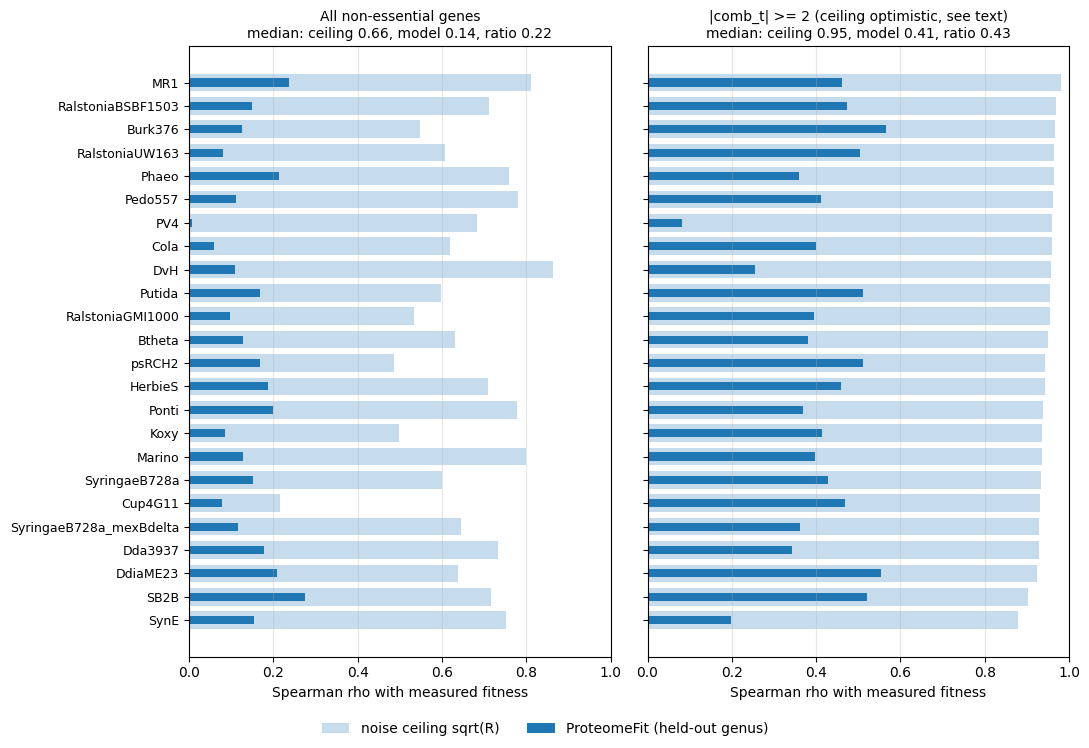

r_half_all    0.283
ceil_all      0.664
model_all     0.139
frac_all      0.219
r_half_sig    0.814
ceil_sig      0.947
model_sig     0.413
frac_sig      0.435


In [5]:
def sb_ceiling(a, b):
    """두 반쪽 값 [m] x 2 -> (반쪽 간 Spearman r, 전체 신뢰도 R = 2r/(1+r), 천장 sqrt(R))"""
    r = spearmanr(a, b)[0]
    R = 2 * r / (1 + r)
    return r, R, np.sqrt(max(R, 0))


rows = []
r0 = model_rho(MU_S, Y_S, ABST, ORG_S, GEN_S, 0)                           # 전 유전자 모델 ρ (균주별)
for o, d in H.groupby('org_id', sort=False):
    s = d[d.comb_t.abs() >= T_SEL]
    ra, Ra, ca = sb_ceiling(d.fit_a, d.fit_b)
    rs, Rs, cs = sb_ceiling(s.fit_a, s.fit_b)
    rows.append(dict(org_id=o, genus=G_OF[o], n_all=len(d), r_half_all=ra, R_all=Ra, ceil_all=ca, model_all=r0[o],
                     n_sig=len(s), r_half_sig=rs, R_sig=Rs, ceil_sig=cs, model_sig=r2[o]))
CEIL = pd.DataFrame(rows)
CEIL['frac_all'], CEIL['frac_sig'] = CEIL.model_all / CEIL.ceil_all, CEIL.model_sig / CEIL.ceil_sig
CEIL.round(4).to_csv(os.path.join(NOISE_DIR, 'ceiling.csv'), index=False)

C = CEIL.sort_values('ceil_sig').reset_index(drop=True)
fig, axs = plt.subplots(1, 2, figsize=(11, 7.5), sharey=True)
for a, sfx, ttl in ((axs[0], 'all', 'All non-essential genes'), (axs[1], 'sig', f'|comb_t| >= {T_SEL:g} (ceiling optimistic, see text)')):
    yy = np.arange(len(C))
    a.barh(yy, C[f'ceil_{sfx}'], height=.75, color='C0', alpha=.25, label='noise ceiling sqrt(R)')
    a.barh(yy, C[f'model_{sfx}'], height=.35, color='C0', label='ProteomeFit (held-out genus)')
    a.set_title(f"{ttl}\nmedian: ceiling {C[f'ceil_{sfx}'].median():.2f}, model {C[f'model_{sfx}'].median():.2f}, "
                f"ratio {C[f'frac_{sfx}'].median():.2f}", fontsize=10)
    a.set_xlim(0, 1)
    a.set_xlabel('Spearman rho with measured fitness')
    a.grid(axis='x', alpha=.3)
axs[0].set_yticks(np.arange(len(C)), C.org_id, fontsize=9)
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=10, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(os.path.join(NOISE_DIR, 'fig2_noise_ceiling.png'), dpi=200)
plt.show()
print(CEIL[['r_half_all', 'ceil_all', 'model_all', 'frac_all', 'r_half_sig', 'ceil_sig', 'model_sig', 'frac_sig']]
      .median().round(3).to_string())


**해석**

- **전 유전자 (왼쪽)** — 반쪽 간 $r_{AB}$ 중앙값 0.28 → 천장 0.66 이다. 모델은 0.14 로 천장의 약 22% 다.
  라벨 대부분이 잡음이라 전 유전자 Spearman 은 모델 능력보다 라벨 품질에 크게 눌린다. 03 노트북의 `_all` 지표가 낮게 나오는 것은 이 때문이다
- **`|comb_t| ≥ 2` (오른쪽)** — 반쪽 간 $r_{AB}$ 0.81, 천장 0.95 (낙관적), 모델 0.41 로 천장의 43% 이상이다.
  이 집합에서는 라벨이 거의 재현되므로, 남은 격차는 **라벨 잡음이 아니라 모델이 아직 맞히지 못하는 부분**이다
- 즉 `|comb_t| ≥ 2` 로 평가해야 지표가 라벨 잡음이 아닌 모델 성능을 반영한다
- 균주별로는 PV4 · SynE · DvH 의 모델 값이 천장에 비해 특히 낮다. 천장은 다른 균주와 비슷하므로 라벨 문제가 아니라 이 균주들의 예측이 어려운 것이다
- 모델 값 0.41 은 24균주의 **중앙값**이라, 28 genus 평균인 0.384 와 집계 방식이 다르다


## 5. 반쪽 산점도 (보조 그림)

A 반쪽의 $|t_A|$ 구간별로 $fit_A$ (가로) 와 $fit_B$ (세로) 를 육각 밀도 그림(hexbin, 색 = 육각형 안 유전자 수, 로그 눈금, 네 패널 공통 범위)으로 그린다. 패널은 가로 · 세로 눈금이 같은 정사각형이다.
점선은 완벽 재현 ($fit_B = fit_A$) 이다. 이 그림은 A 로 고르고 B 로 확인하는 한 방향만 쓴다.


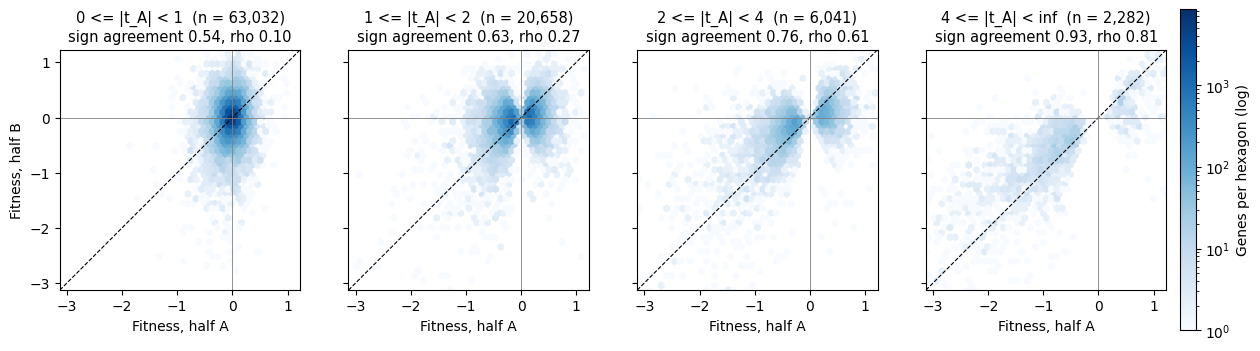

In [6]:
BINS = [(0, 1), (1, 2), (2, 4), (4, np.inf)]                              # |t_A| 구간
lo, hi = np.nanpercentile(np.r_[H.fit_a, H.fit_b], [0.2, 99.9])
fig, axs = plt.subplots(1, 4, figsize=(17, 4.9), sharex=True, sharey=True)
hbs = []
for a, (b0, b1) in zip(axs, BINS):
    d = H[(H.t_a.abs() >= b0) & (H.t_a.abs() < b1)]                        # A 반쪽 |t| 로 고른 유전자
    hbs.append(a.hexbin(d.fit_a, d.fit_b, gridsize=45, extent=(lo, hi, lo, hi), bins='log', cmap='Blues', mincnt=1))
    a.set_xlim(lo, hi); a.set_ylim(lo, hi); a.set_aspect('equal')          # 패널마다 정사각 (가로 · 세로 같은 눈금)
    a.plot([lo, hi], [lo, hi], 'k--', lw=.8)
    a.axhline(0, color='grey', lw=.6); a.axvline(0, color='grey', lw=.6)
    agree = (np.sign(d.fit_a) == np.sign(d.fit_b)).mean()
    a.set_title(f"{b0:g} <= |t_A| < {b1:g}  (n = {len(d):,})\nsign agreement {agree:.2f}, rho {spearmanr(d.fit_a, d.fit_b)[0]:.2f}",
                fontsize=10.5)
    a.set_xlabel('Fitness, half A')
axs[0].set_ylabel('Fitness, half B')
vmax = max(h.get_array().max() for h in hbs)                              # 네 패널 공통 색 범위 (육각형당 최대 유전자 수)
for h in hbs:
    h.set_clim(1, vmax)
fig.colorbar(hbs[-1], ax=axs, shrink=.85, pad=.01, label='Genes per hexagon (log)')
fig.savefig(os.path.join(NOISE_DIR, 'fig3_halves_hexbin.png'), dpi=200, bbox_inches='tight')
plt.show()


**해석**

- **$|t_A| < 1$** (63,032개, 반쪽 유전자의 69%) — 원점 주변의 둥근 구름이다. A 와 B 가 거의 무관하다 (부호 일치 0.54, $\rho$ 0.10)
- **$1 \le |t_A| < 2$** — 가로로 두 덩어리가 생긴 것은 $|t_A|$ 로 골라 $fit_A \approx 0$ 이 빠졌기 때문이다. 세로($fit_B$)는 여전히 0 중심에 퍼져 있어 재현이 약하다 (0.63, 0.27)
- **$2 \le |t_A| < 4$** — 덩어리가 대각선을 따라 기울기 시작한다 (0.76, 0.61)
- **$|t_A| \ge 4$** — 대각선을 따라 놓인다 (0.93, 0.81). 대부분 **음의 적합도(결손 시 생장 저하)** 이며, 강한 양의 효과는 드물다
- 큰 $|fit_A|$ 의 B 값은 대각선보다 조금 0 쪽에 놓인다. 한 번 크게 측정된 값은 다시 재면 작아지는 **평균으로의 회귀**이며,
  같은 자료로 고르고 재면 재현성이 부풀려지는 이유다 (도입부 설계)


## 6. 평가 기준값에 따른 모델 성능 (보조 그림)

학습된 모델은 그대로 두고 **평가 집합의 기준 $\tau$ 만** 0 – 4 로 바꿔, 서비스 적합도 모델의 시험 Spearman (genus 평균 ± 표준편차, 28 genus) 과
평가 유전자 수 (오른쪽 축, 로그 눈금) 를 본다. 기준값을 성능이 좋아 보이도록 고른 것이 아닌지 확인하는 민감도 분석이다.


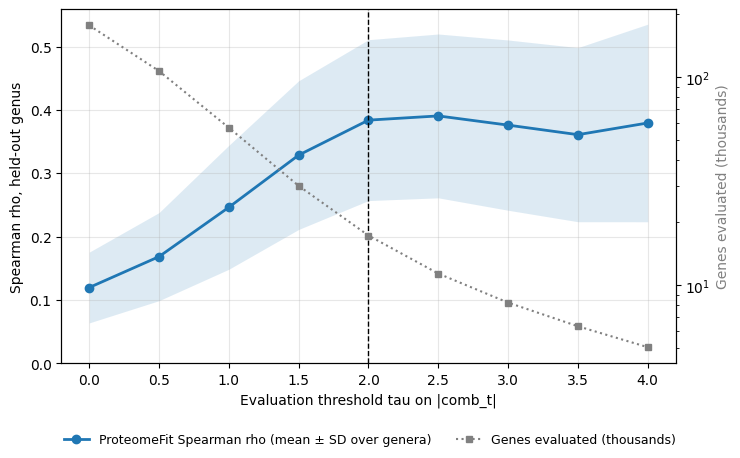

 tau   rho  rho_sd  n_genus  kept_n
 0.0 0.120   0.056       28  177317
 0.5 0.168   0.070       28  106947
 1.0 0.246   0.098       28   57097
 1.5 0.329   0.117       28   30000
 2.0 0.384   0.127       28   17311
 2.5 0.390   0.129       28   11358
 3.0 0.376   0.134       28    8235
 3.5 0.361   0.137       28    6339
 4.0 0.379   0.156       28    5029


In [7]:
TS = np.round(np.arange(0, 4.01, 0.5), 2)
rows = []
for t in TS:
    g = model_rho(MU_S, Y_S, ABST, ORG_S, GEN_S, t)
    g = g.groupby(g.index.map(G_OF)).mean()                                # genus 평균 [28]
    rows.append(dict(tau=t, rho=g.mean(), rho_sd=g.std(), n_genus=int(g.notna().sum()), kept_n=int((ABST >= t).sum())))
SENS = pd.DataFrame(rows)
SENS.round(4).to_csv(os.path.join(NOISE_DIR, 'sensitivity.csv'), index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.fill_between(SENS.tau, SENS.rho - SENS.rho_sd, SENS.rho + SENS.rho_sd, color='C0', alpha=.15, lw=0)
ax.plot(SENS.tau, SENS.rho, 'C0o-', lw=2, label='ProteomeFit Spearman rho (mean ± SD over genera)')
ax.set_ylabel('Spearman rho, held-out genus')
ax.set_xlabel('Evaluation threshold tau on |comb_t|')
ax.axvline(T_SEL, color='k', ls='--', lw=1)
ax.set_ylim(0, None)
ax.grid(alpha=.3)
bx = ax.twinx()
bx.plot(SENS.tau, SENS.kept_n / 1e3, color='grey', ls=':', marker='s', ms=4, label='Genes evaluated (thousands)')
bx.set_ylabel('Genes evaluated (thousands)', color='grey')
bx.set_yscale('log')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = bx.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc='lower center', ncol=2, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(os.path.join(NOISE_DIR, 'fig4_threshold_sensitivity.png'), dpi=200)
plt.show()
print(SENS.round(3).to_string(index=False))


**해석**

- 모델 Spearman 은 0.120 ($\tau = 0$) → 0.246 ($\tau = 1$) → 0.384 ($\tau = 2$) 로 오른 뒤, 0.390 (2.5) · 0.376 (3) · 0.361 (3.5) · 0.379 (4) 로 평탄하다
- 상승 구간의 모양이 2절의 반쪽 간 $\rho$ 와 같다. 낮은 기준에서의 낮은 성능은 모델보다 **라벨 잡음** 탓이다
- 2 는 성능을 최대로 만드는 값이 아니다 (최댓값은 2.5 의 0.390, 차이 0.006). 2 이상에서는 기준을 바꿔도 결론이 같고 평가 유전자 수만 줄어든다 (17,311 → 5,029)
- 기준을 올릴수록 표준편차가 커지는 것은 genus 마다 평가 유전자가 줄어 추정이 불안정해지기 때문이다


## 7. 정리 — `|comb_t| ≥ 2` 를 쓰는 근거

1. **라벨 일관성** — 독립 반쪽 간 순위 재현성 ($\rho$) 이 $\tau = 2$ 에서 평탄 구간(0.81 – 0.83)의 약 93% 에 이른다. 부호 일치율은 0.86 이다 (2절)
2. **샘플 규모** — 2 에서 17,311개 (9.8%) 가 남는다. 4 로 올리면 5,029개로 줄지만 재현성 이득은 작다 (2절)
3. **평가 지표의 의미** — 이 집합에서는 라벨이 거의 재현되므로 지표가 라벨 잡음이 아닌 모델 성능을 반영한다 (4절).
   모델 성능도 2 에서 평탄해지므로 기준값 선택이 결과를 부풀리지 않는다 (6절)
4. **통계적 의미** — 2 는 양측 약 5% 유의수준에 해당한다. Fitness Browser 는 보통 $|t| < 4$ 인 효과를 무시하는데, 그 기준은 **단일 실험** 값에 대한 것이다.
   여기서는 무자극 반복 실험을 결합한 `comb_t` 하나만 보므로 더 낮은 기준이 정당화된다는 것이 위 결과의 뜻이다 (추정 — Fitness Browser 가 4 를 고른 근거는 확인하지 못했다)

- 학습에서는 `|comb_t| < 2` 유전자도 버리지 않고 `clip(|comb_t|, 0.3, 3)` 가중치로 덜 반영한다. 2 는 조기 종료 · 평가 집합의 기준이다 (03 노트북)
- 한계 — 반쪽 분할이 가능한 24균주에서 얻은 결과이고, 반쪽 $t$ 의 재현성을 전체 `comb_t` 기준으로 옮겨 읽는 것은 근사다
